<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financiado pela União Europeia** · Programa de Parceria Espacial África–UE · Reforço dos Alertas Precoces em África (SEWA)

# A estação das chuvas de 2024 no Senegal, no ERA5 🌧️
### Serviço Copernicus para as Alterações Climáticas · ERA5 · conta gratuita

> ⚠️ **Tradução:** este notebook foi traduzido do inglês com a ajuda de IA e revisto na medida do possível. Em caso de dúvida, prevalece a [versão inglesa](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5.ipynb). Comunique quaisquer erros no [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5_pt.ipynb)

A estação das chuvas de 2024 (junho a outubro) foi mais húmida do que um ano normal? Este notebook usa as **médias
mensais do ERA5**, a reanálise Copernicus que o ECMWF produz para a União Europeia, para comparar 2024 com a média
1991–2020, em percentagem do normal. O rio Senegal nasce nos planaltos da Guiné e do Mali, por isso o mapa cobre toda
a sua bacia.

**O que precisa:** uma conta Google (para usar o Colab) e uma conta Copernicus gratuita (passo abaixo). Tudo corre nos computadores da Google: os dados são descarregados lá, não no seu telemóvel
ou computador, por isso uma ligação lenta ou móvel é suficiente.

| Dados | O que este notebook usa | Licença |
|---|---|---|
| Médias mensais do ERA5, cerca de 31 km | Precipitação total, junho–outubro, 1991–2024 | licença Copernicus, gratuito |

**Ferramentas:** [earthkit](https://earthkit.ecmwf.int), as ferramentas Python gratuitas e de código aberto do ECMWF para dados meteorológicos e climáticos.

*Clique em **Ambiente de execução → Executar tudo** (Runtime → Run all). O data store coloca os pedidos em fila: o passo 2 pode demorar alguns minutos.*

<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/c3s_logoline_pos.png" alt="Copernicus, implemented by ECMWF" height="30"/>

In [ ]:
# Instalar as ferramentas de código aberto (Colab / máquina nova). Alguns minutos da primeira vez.
%pip install -q "earthkit-data[cds]" earthkit-plots

## A sua chave Copernicus gratuita

Os dados Copernicus são gratuitos e abertos, mas os data stores pedem um registo único para gerir a fila de pedidos:
1. Crie uma conta em [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (a mesma conta serve para o
   Atmosphere Data Store).
2. Abra a [página do conjunto de dados](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download) no Climate Data Store e aceite a licença (no fundo do separador Download). Só precisa de o fazer uma vez.
3. Copie a sua chave API da sua [página de perfil](https://cds.climate.copernicus.eu/profile) e cole-a abaixo.

**Use a sua própria chave.** Cada pessoa que executa este notebook precisa da sua própria conta e chave Copernicus
gratuitas. A célula seguinte pede a chave numa caixa oculta e guarda-a na máquina que executa o notebook (no Colab, uma
máquina temporária apagada quando fecha o separador). A chave nunca fica guardada no notebook: não a cole numa célula de
código e não partilhe um notebook ou captura de ecrã que a mostre. No seu computador, se `~/.cdsapirc` / `~/.adsapirc`
já existirem, a célula não pede nada.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Chave API Copernicus: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Chave Copernicus pronta")

Chave Copernicus pronta


In [3]:
import pyproj                     # importar antes de earthkit.data (evita um erro ao fechar)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

DIAS = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro",
         "novembro", "dezembro"]
def dia(d): return f"{DIAS[d.weekday()]}, {d.day} de {MESES[d.month - 1]}"     # datas em português
def data_pt(d): return f"{d.day} de {MESES[d.month - 1]} de {d.year}"

## 1 · Escolher a estação, o ano e a área

In [4]:
AREA   = [18.0, -18.5, 9.0, -6.0]                     # norte, oeste, sul, este
YEAR   = 2024
MONTHS = ["06", "07", "08", "09", "10"]               # junho a outubro
DAYS   = {"06": 30, "07": 31, "08": 31, "09": 30, "10": 31}
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Descarregar a precipitação mensal do ERA5, 1991–2020 e o ano escolhido

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-single-levels-monthly-means", {
    "product_type": "monthly_averaged_reanalysis", "variable": "total_precipitation",
    "year": [str(y) for y in range(1991, 2021)] + [str(YEAR)], "month": MONTHS, "time": "00:00",
    "area": AREA, "data_format": "grib"}).to_xarray()
tp = era[list(era.data_vars)[0]]                                   # metros por dia, média mensal
tdim = [d for d in tp.dims if d not in ("latitude", "longitude")][0]
t = tp[tdim].dt
mm = tp * 1000 * tp[tdim].dt.days_in_month                       # -> mm em cada mês
season = mm.groupby(t.year).sum(tdim)                             # mm de junho a outubro, em cada ano
normal = season.sel(year=slice(1991, 2020)).mean("year")
this = season.sel(year=YEAR)
pct = 100 * this / normal
print(f"{YEAR}: {float(this.mean()):.0f} mm na área, normal {float(normal.mean()):.0f} mm "
      f"({float(100 * this.mean() / normal.mean()):.0f}% do normal)")
for n, la, lo in CITIES:
    print(f"  {n:12s} {float(this.sel(latitude=la, longitude=lo, method='nearest')):5.0f} mm, "
          f"{float(pct.sel(latitude=la, longitude=lo, method='nearest')):4.0f}% do normal")

2024: 916 mm na área, normal 752 mm (122% do normal)
  Dakar          480 mm,  175% do normal
  Saint-Louis    101 mm,   70% do normal
  Touba          388 mm,  103% do normal
  Tambacounda    634 mm,  109% do normal
  Ziguinchor    1445 mm,  122% do normal
  Kédougou       849 mm,  104% do normal


## 3 · Cartografá-la

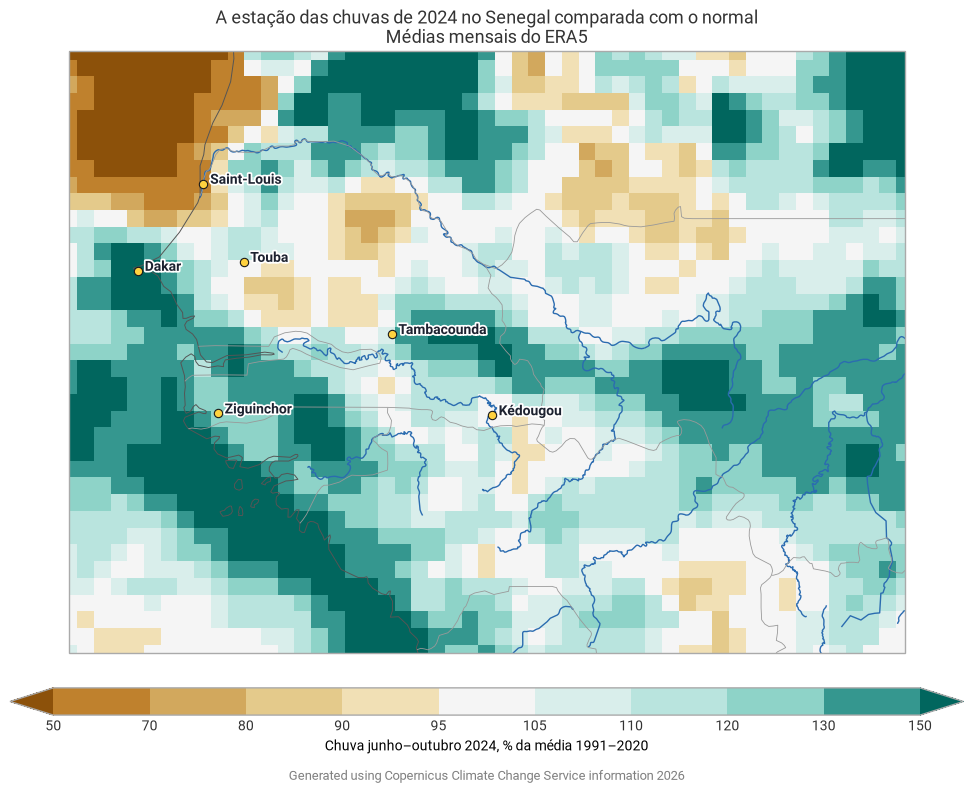

In [6]:
colors = ["#8c510a", "#bf812d", "#dfc27d", "#f6e8c3", "#f5f5f5", "#c7eae5", "#80cdc1", "#35978f", "#01665e"]
style = ekp.styles.Style(levels=[50, 70, 80, 90, 95, 105, 110, 120, 130, 150], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 7.5))
chart.pcolormesh(pct, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
chart.ax.add_feature(__import__("cartopy").feature.RIVERS, edgecolor="#2b6cb0", linewidth=1.0)
label_cities(chart.ax)
chart.legend(label=f"Chuva junho–outubro {YEAR}, % da média 1991–2020")
chart.title(f"A estação das chuvas de {YEAR} no Senegal comparada com o normal\nMédias mensais do ERA5", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("rain_era5_pt.png")
chart.show()

## 4 · A sua vez 🌍

- **Outro ano:** `YEAR = 2020` ou qualquer ano desde 1940.
- **Só os meses mais chuvosos:** `MONTHS = ["08", "09"]`.
- **Mais quente ou mais fresco do que o normal:** `"2m_temperature"` (kelvin) e `this - normal` em vez de uma percentagem.

### Dados e licença
Os dados Copernicus são gratuitos e abertos sob a licença Copernicus (CC-BY 4.0). Crédito:
*Generated using Copernicus Climate Change Service information 2026.* O ECMWF opera o Serviço de Monitorização da Atmosfera do Copernicus (CAMS) e o
Serviço Copernicus para as Alterações Climáticas (C3S) em nome da União Europeia.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)